In [57]:
import numpy as np
import matplotlib.pyplot as plt

In [58]:
def load_mnist_images(filename):
    data = np.fromfile(filename, dtype = np.uint8, offset = 16)
    return data.reshape(-1, 28, 28)

def load_mnist_labels(filename):
    return np.fromfile(filename, dtype = np.uint8, offset = 8)

X_train = load_mnist_images("train-images.idx3-ubyte")
y_train = load_mnist_labels("train-labels.idx1-ubyte")

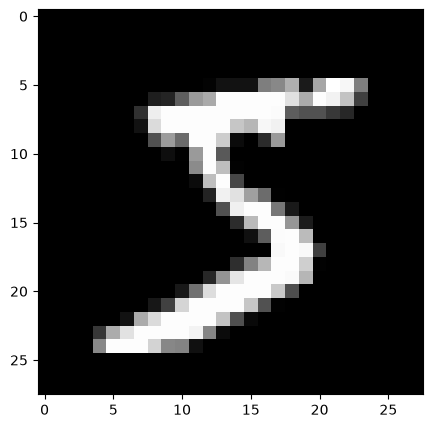

In [59]:
temp_grid = X_train[0]
plt.figure(figsize = (5, 5))
plt.imshow(temp_grid, cmap = "gray", vmin = 0, vmax = 255)
plt.show()

In [60]:
input_size = 784
hidden_size = 128
output_size = 10

def init_parameters(hidden_size, seed = 42):
    np.random.seed(42)
    w1 = np.random.randn(784, hidden_size) * np.sqrt(2/784)
    b1 = np.zeros([1, hidden_size])
    w2 = np.random.randn(hidden_size, 10) * np.sqrt(2/hidden_size)
    b2 = np.zeros([1, 10])
    return w1, b1, w2, b2

w1, b1, w2, b2 = init_parameters(hidden_size)
X_train = X_train.reshape(X_train.shape[0], -1).astype(np.float32) / 255.0 

In [61]:
def ReLU(Z):
    return np.maximum(0, Z)

def ReLU_derivative(Z):
    return (Z > 0).astype(float)

def softmax(Z):
    e = np.exp(Z - Z.max(axis = 1, keepdims = True))
    return e / e.sum(axis = 1, keepdims = True)

In [62]:
def forward_pass(X, w1, w2, b1, b2):
    z1 = X @ w1 + b1
    a1 = ReLU(z1)
    z2 = a1 @ w2 + b2
    a2 = softmax(z2)
    return a2, [z1, a1, z2, a2]

In [63]:
def one_hot_encode(y):
    one_hot_y = np.zeros((y.size, y.max() + 1))
    one_hot_y[np.arange(y.size), y] = 1
    return one_hot_y

def cross_entropy_loss(y_pred, y):
    m = y.size
    y = one_hot_encode(y)
    return -np.sum(y * np.log(y_pred + 1e-9)) / m

def backpropagation(X, y, cache, w1, w2):
    z1, a1, z2, a2 = cache
    m = y.size
    y = one_hot_encode(y)
    dz2 = a2 - y
    dw2 = (a1.T @ dz2) / m
    db2 = np.sum(dz2, axis = 0, keepdims = True) / m
    dz1 = (dz2 @ w2.T) * ReLU_derivative(z1)
    dw1 = (X.T @ dz1) / m
    db1 = np.sum(dz1, axis = 0, keepdims = True) / m
    return dw2, dw1, db2, db1


In [64]:
learning_rate = 0.1
epochs = 20
m = X_train.shape[0]
batch_size = 128
for epoch in range(epochs):
    perm = np.random.permutation(m)
    X_shuf, y_shuf = X_train[perm], y_train[perm]
    for i in range(0, m, batch_size):
        Xb = X_shuf[i:i+batch_size]
        yb = y_shuf[i:i+batch_size]
        a2, cache = forward_pass(Xb, w1, w2, b1, b2)
        dw2, dw1, db2, db1 = backpropagation(Xb, yb, cache, w1, w2)
        w1 -= dw1 * learning_rate
        w2 -= dw2 * learning_rate
        b1 -= db1 * learning_rate
        b2 -= db2 * learning_rate
    a2_pred, _ = forward_pass(X_train, w1, w2, b1, b2)
    loss = cross_entropy_loss(a2_pred, y_train)
    print(loss)


0.2997007116387209
0.22922790727411693
0.1882281955468658
0.15809254384034835
0.13909431417247706
0.12517918486788732
0.11160495166604081
0.09954416116738994
0.09347314995124441
0.08606220328686409
0.08067826844681442
0.07239521362552911
0.0681729048185186
0.06431450615973681
0.06069425027164805
0.057899258393767625
0.05501949355969331
0.051831996353962066
0.05082424400284756
0.04667624117489676


In [69]:
X_test = load_mnist_images("t10k-images.idx3-ubyte")
X_test = X_test.reshape(X_test.shape[0], -1).astype(np.float32) / 255.0 
y_test = load_mnist_labels("t10k-labels.idx1-ubyte")
y_test = y_test.astype(int)

a2_test, _ = forward_pass(X_test, w1, w2, b1, b2)
preds = a2_test.argmax(axis=1)

print("test loss:", cross_entropy_loss(a2_test, y_test))
print("test accuracy:", np.mean(preds == y_test))

test loss: 0.07552427152746495
test accuracy: 0.9777


In [76]:
digit = np.array([
    [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
    [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
    [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
    [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
    [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
    [  0,   0,   0,   0,   0,   0,   0,   0,   0,  80, 190, 240, 255, 250, 210, 110,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
    [  0,   0,   0,   0,   0,   0,   0,   0, 130, 245, 255, 180,   0,   0, 150, 250, 220,  90,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
    [  0,   0,   0,   0,   0,   0,   0,   0,  90, 170,   0,   0,   0,   0,   0,   0, 180, 255, 160,   0,   0,   0,   0,   0,   0,   0,   0,   0],
    [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0, 140, 255, 200,   0,   0,   0,   0,   0,   0,   0,   0,   0],
    [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0, 180, 255, 150,   0,   0,   0,   0,   0,   0,   0,   0,   0],
    [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0, 150, 250, 210,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
    [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  90, 210, 255, 160,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
    [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0, 140, 230, 255, 255, 200,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
    [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0, 160, 250, 255, 255, 240, 140,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
    [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0, 130, 240, 255, 180,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
    [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0, 180, 255, 210,   0,   0,   0,   0,   0,   0,   0,   0,   0],
    [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0, 210, 255, 170,   0,   0,   0,   0,   0,   0,   0,   0,   0],
    [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0, 200, 255, 180,   0,   0,   0,   0,   0,   0,   0,   0,   0],
    [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0, 210, 255, 150,   0,   0,   0,   0,   0,   0,   0,   0,   0],
    [  0,   0,   0,   0,   0,   0,   0,   0,  80,   0,   0,   0,   0,   0,   0,   0, 160, 255, 210,   0,   0,   0,   0,   0,   0,   0,   0,   0],
    [  0,   0,   0,   0,   0,   0,   0, 150, 240, 160,   0,   0,   0,   0,   0, 130, 245, 220,  90,   0,   0,   0,   0,   0,   0,   0,   0,   0],
    [  0,   0,   0,   0,   0,   0,   0, 140, 255, 245, 170,   0,   0, 120, 220, 255, 190,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
    [  0,   0,   0,   0,   0,   0,   0,   0,  90, 200, 255, 255, 255, 255, 240, 140,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
    [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0, 100, 180, 200, 170,  90,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
    [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
    [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
    [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
    [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0]
], dtype=np.uint8)

x = digit.reshape(1, 784) / 255.0

prediction, _ = forward_pass(x, w1, w2, b1, b2)
print(prediction.argmax())


3
